# Лабораторная работа №2: классификация
## 1. Знакомство с данными

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [3]:
URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(URL)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Первичный анализ данных

Каждая строка — один пассажир. Целевая переменная — `Survived` (1 — выжил, 0 — нет).
Остальные колонки: класс билета `Pclass`, имя `Name`, пол `Sex`, возраст `Age`,
число родственников на борту (`SibSp` — братья/сёстры/супруги, `Parch` — родители/дети),
номер билета `Ticket`, цена `Fare`, каюта `Cabin`, порт посадки `Embarked`.+

In [8]:
df.info()

missing = df.isna().sum()
missing = missing[missing > 0]
print("Пропуски по столбцам:")
print(pd.DataFrame({"пропусков": missing, "доля, %": (missing / len(df) * 100).round(1)}).to_string())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
Пропуски по столбцам:
          пропусков  доля, %
Age             177     19.9
Cabin           687     77.1
Embarked          2      0.2


### Вывод по типам данных и пропускам

В таблице 891 строка. Пропуски есть в трёх столбцах: `Cabin` — 687 значений (77,1%), `Age` — 177 (19,9%) и `Embarked` — всего 2.

У `Cabin` пропущено больше трёх четвертей данных, поэтому восстанавливать номер каюты бессмысленно. Но сам факт, известна каюта или нет, может быть полезен: вероятно, каюта чаще записана у пассажиров первого класса.

Пропуски в `Age` (около пятой части данных) удалять нельзя, иначе потеряем 177 пассажиров. Поэтому возраст заполняю. Пропуски в `Embarked` заполняю самым частым значением, потому что их всего 2.

Числовые признаки: `PassengerId`, `Survived`, `Pclass`, `Age`, `SibSp`, `Parch`, `Fare` (форматы `int64` и `float64`). Текстовые: `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`. Текстовые признаки, а модели работают только с числами, поэтому их нужно закодировать в числа или превратить в числовые признаки.

In [9]:
print("Дубликаты строк:", df.duplicated().sum())
print("Дубликаты без PassengerId:", df.drop(columns="PassengerId").duplicated().sum())

Дубликаты строк: 0
Дубликаты без PassengerId: 0


### Вывод по дубликатам

Полных дубликатов нет: все строки уникальны. Проверка без `PassengerId` тоже показала, что повторов нет, хотя этот столбец уникален для каждой строки и мог бы скрыть повторы одного и того же пассажира. Удалять ничего не нужно.

In [10]:
print(df.nunique().sort_values(ascending=False).to_string())

PassengerId    891
Name           891
Ticket         681
Fare           248
Cabin          147
Age             88
SibSp            7
Parch            7
Embarked         3
Pclass           3
Survived         2
Sex              2


### Вывод по уникальным значениям

У `PassengerId` и `Name` по 891 разных значений, то есть у каждого пассажира своё. У `Ticket` 681 из 891, у `Cabin` 147 из 204 известных. Такие признаки почти однозначно указывают на конкретного человека: модель может просто запомнить пассажиров из train, а на новых людях это не поможет. Поэтому в сыром виде не будем их учитывать.

`PassengerId` — это просто айди в файле, он вообще не связан с пассажиром. Но из `Name` можно извлечь титул (`Mr`, `Mrs`, `Miss`, `Master`): он показывает пол и примерный возраст, и таких значений немного.

`Sex`, `Embarked`, `Pclass` — категориальные признаки с 2–3 значениями. `Pclass` уже число, а `Sex` и `Embarked` нужно закодировать в числа.

Survived
0    549
1    342
Доля выживших: 0.384


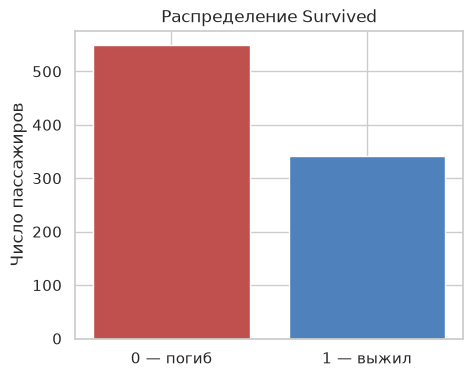

In [11]:
counts = df["Survived"].value_counts().sort_index()
print(counts.to_string())
print("Доля выживших:", round(df["Survived"].mean(), 3))

plt.figure(figsize=(5, 4))
plt.bar(["0 — погиб", "1 — выжил"], counts, color=["#c0504d", "#4f81bd"])
plt.title("Распределение Survived")
plt.ylabel("Число пассажиров")
plt.show()

### Вывод по целевой переменной

Погибли 549 пассажиров (62%), выжили 342 (38%). Классы несбалансированы: погибших примерно в 1.6 раза больше.

Из-за этого Accuracy может обманывать: модель, которая всем говорит «погиб», уже угадает 62% пассажиров, хотя не найдёт ни одного выжившего. Поэтому основная метрика — F1 для класса 1, она учитывает и Precision (насколько можно верить ответу «выжил»), и Recall (какую долю выживших модель нашла).

Дисбаланс умеренный, поэтому при разбиении на train и test использую `stratify`, чтобы доля выживших в обеих частях была одинаковой.

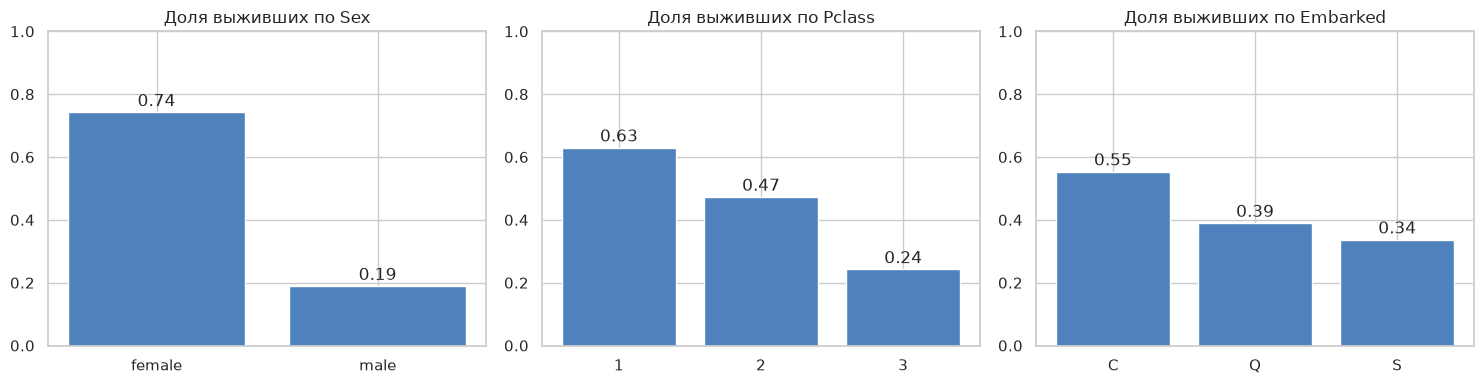

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    rate = df.groupby(col)["Survived"].mean()
    ax.bar(rate.index.astype(str), rate, color="#4f81bd")
    ax.set_title(f"Доля выживших по {col}")
    ax.set_ylim(0, 1)
    for i, v in enumerate(rate):
        ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.show()

### Вывод по полу, классу и порту посадки

Сильнее всего на выживание влияет пол: среди женщин выжили 74%, среди мужчин только 19%.

Класс тоже сильно влияет: в 1-м классе выжили 63%, во 2-м 47%, в 3-м 24%. Пассажиры 1-го класса жили на верхних палубах, ближе к шлюпкам.

По порту посадки разница меньше: больше всего выживших среди севших в С (55%). Скорее всего, сам порт не влияет, проверим это.

In [13]:
print("Число пассажиров по портам:")
print(df["Embarked"].value_counts().to_string())
print()
print("Доля каждого класса среди севших в порту:")
print(pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").round(2))

Число пассажиров по портам:
Embarked
S    644
C    168
Q     77

Доля каждого класса среди севших в порту:
Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55


### Вывод по составу пассажиров по портам

Больше всего выживших среди севших в C (55%), хотя там сели всего 168 человек из 889. Причина не в самом порте: в C 51% пассажиров ехали 1-м классом, а в S — только 20%. Порт Q по доле выживших (39%) выше S, хотя там 94% пассажиров 3-го класса, но там всего 77 человек, поэтому разница может быть случайной.

Получается, что `Embarked` связан с выживанием в основном через класс. Такая связь называется косвенной: сам порт не влияет на выживание, а коррелирует с классом, который на него влияет (класс здесь — смешивающий фактор).

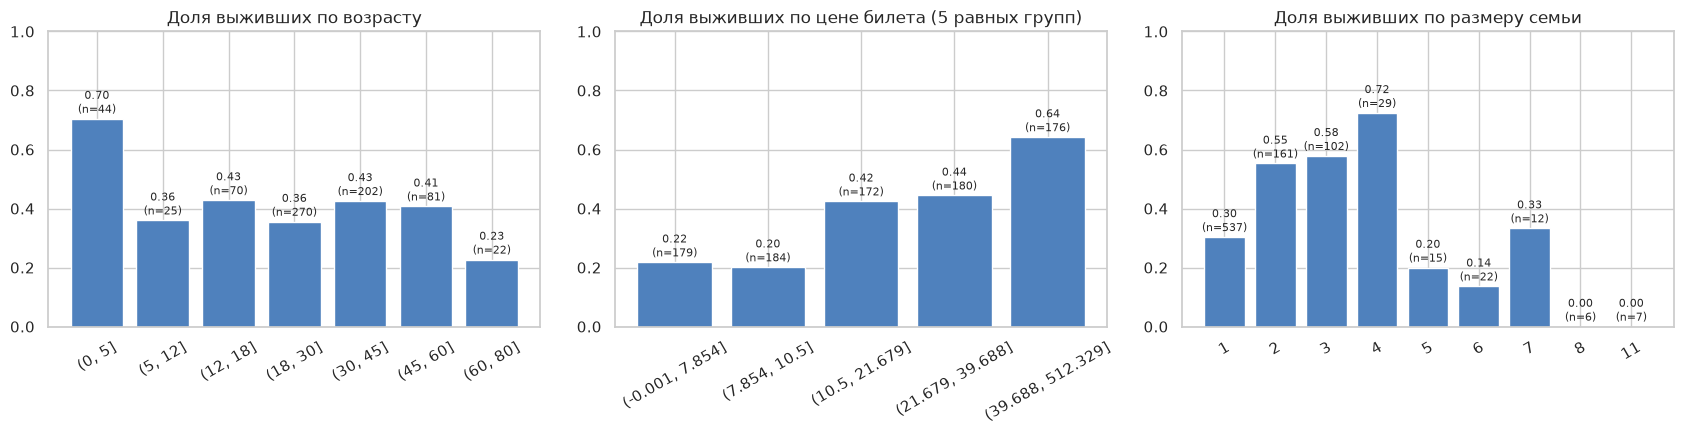

Fare: медиана 14.4542  максимум 512.3292


In [15]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

age_group = pd.cut(df["Age"], bins=[0, 5, 12, 18, 30, 45, 60, 80])
fare_group = pd.qcut(df["Fare"], q=5)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, group, title in zip(axes,
                            [age_group, fare_group, df["FamilySize"]],
                            ["возрасту", "цене билета (5 равных групп)", "размеру семьи"]):
    stats = df.groupby(group, observed=True)["Survived"].agg(["mean", "size"])
    ax.bar(stats.index.astype(str), stats["mean"], color="#4f81bd")
    for i, (v, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(i, v + 0.02, f"{v:.2f}\n(n={n})", ha="center", fontsize=8)
    ax.set_title(f"Доля выживших по {title}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Fare: медиана", df["Fare"].median(), " максимум", df["Fare"].max())

### Вывод по возрасту, цене билета и размеру семьи

**Age:** у маленьких детей до 5 лет выжили 70%, это самая высокая доля среди всех возрастов. У взрослых от 18 до 60 лет выжили 36–43%, а у пожилых старше 60 лет только 23%. Связь возраста с выживанием нелинейная: важен не столько возраст, сколько то, ребёнок ли пассажир.

**Fare:** медиана цены 14,45, а максимум 512,33, распределение сильно скошено вправо, поэтому в модели буду использовать логарифм. В двух самых дешёвых группах выжили около 20%, а в самой дорогой — 64%. Это связано с классом: дорогие билеты были в 1-м классе.

**FamilySize:** у пассажиров, которые ехали одни, доля выживших 30%; лучше всего выживали семьи из 2–4 человек (до 72%), а у семей из 5 и больше доля выживших очень мала. Одиночкам, возможно, никто не помогал, а большой семье было трудно собраться вместе. Для семей из 8 и 11 человек данных мало (n = 6 и 7), поэтому 0% там может быть случайностью.

In [16]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
print(df["Title"].value_counts().to_string())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1


In [17]:
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

title_stats = df.groupby("Title").agg(
    пассажиров=("Survived", "size"),
    доля_выживших=("Survived", "mean"),
    медиана_возраста=("Age", "median"),
    пропусков_возраста=("Age", lambda s: s.isna().sum()),
).round(2)
title_stats

,пассажиров,доля_выживших,медиана_возраста,пропусков_возраста
Title,,,,
Master,40,0.57,3.5,4
Miss,185,0.70,21.0,36
Mr,517,0.16,30.0,119
Mrs,126,0.79,35.0,17
Rare,23,0.35,48.5,1


### Вывод по титулам

Титулов 17, но большинство встречается 1–7 раз, поэтому `Mlle` (мадмуазель) и `Ms` объединяю с Miss, `Mme` (мадам) с Mrs, а редкие титулы — в группу Rare.

Титул хорошо разделяет пассажиров: у `Mr` выжили только 16%, у `Mrs` 79 у `Miss` 70%. У `Master` (мальчики) 57% — намного больше, чем у взрослых мужчин, хотя пол тот же. Значит, титул несёт информацию не только о поле, но и о возрасте.

Медиана возраста по титулам сильно отличается: у `Master` 3.5 года, у `Mr` 30, у `Mrs` 35. Поэтому пропуски в `Age` заполняю не общей медианой, а медианой титула. Например, мальчику без возраста общая медиана (28 лет) поставила бы возраст взрослого мужчины, хотя он ребёнок.

## 2. Разбиение на train и test

In [18]:
from sklearn.model_selection import train_test_split

# убираем целевую переменную и столбцы, которые добавляли для анализа
X = df.drop(columns=["Survived", "FamilySize", "Title"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("train:", X_train.shape, " test:", X_test.shape)

dist = pd.DataFrame({
    "весь датасет": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)
dist

train: (712, 11)  test: (179, 11)


,весь датасет,train,test
Survived,,,
0,0.616,0.617,0.615
1,0.384,0.383,0.385


### Вывод по разбиению

Беру 80% данных на обучение и 20% на тест. Тестовую выборку использую только для финальной оценки моделей, все параметры обработки и моделей подбираю по train.

`random_state` фиксирует как перемешались данные, поэтому разбиение одинаковое при каждом запуске и все модели сравниваются на одних и тех же данных.

`stratify=y` делает долю выживших в train и test одинаковой , как во всём датасете. Это важно, потому что тест маленький, и без стратификации доля выживших в нём могла бы случайно сильно отличаться.

## 3. Подготовка признаков

In [20]:
from sklearn.base import BaseEstimator, TransformerMixin


def extract_title(name):
    title = name.split(",")[1].split(".")[0].strip()
    title = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}.get(title, title)
    return title if title in ["Mr", "Mrs", "Miss", "Master"] else "Rare"


NUM_FEATURES = ["Pclass", "Age", "AgeMissing", "SibSp", "Parch",
                "FamilySize", "IsAlone", "HasCabin", "LogFare"]
CAT_FEATURES = ["Sex", "Embarked", "Title"]


class TitanicFeatures(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        titles = X["Name"].map(extract_title)
        self.age_by_title_ = X["Age"].groupby(titles).median()   # медиана возраста по титулу
        self.age_global_ = X["Age"].median()                     # запасной вариант
        return self

    def transform(self, X):
        d = X.copy()
        d["Title"] = d["Name"].map(extract_title)
        d["AgeMissing"] = d["Age"].isna().astype(int)
        d["Age"] = d["Age"].fillna(d["Title"].map(self.age_by_title_)).fillna(self.age_global_)
        d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
        d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
        d["HasCabin"] = d["Cabin"].notna().astype(int)
        d["LogFare"] = np.log1p(d["Fare"])
        return d[NUM_FEATURES + CAT_FEATURES]

In [21]:
fe = TitanicFeatures().fit(X_train)
print("Медианы возраста по титулу (посчитаны по train):")
print(fe.age_by_title_.round(1).to_string())
fe.transform(X_train).head()

Медианы возраста по титулу (посчитаны по train):
Name
Master     3.0
Miss      22.0
Mr        30.0
Mrs       35.0
Rare      49.0


,Pclass,Age,AgeMissing,SibSp,Parch,FamilySize,IsAlone,HasCabin,LogFare,Sex,Embarked,Title
692,3,30.0,1,0,0,1,1,0,4.051712,male,S,Mr
481,2,30.0,1,0,0,1,1,0,0.000000,male,S,Mr
527,1,30.0,1,0,0,1,1,1,5.406181,male,S,Mr
855,3,18.0,0,0,1,2,0,0,2.336987,female,S,Mrs
801,2,31.0,0,1,1,3,0,0,3.305054,female,S,Mrs


### Вывод по подготовке признаков

Все преобразования собраны в один класс `TitanicFeatures`. В `fit` он запоминает медианы возраста только по train, а в `transform` применяет их к любой выборке. Так информация из теста не попадает в обучение.

Как обработаны признаки:
- **Title** извлекаю из `Name`, редкие титулы объединяю в `Rare`. Само имя не использую, потому что оно уникально у каждого пассажира.
- **Age** заполняю медианой возраста по титулу, посчитанной по train: у `Master` это 3 года, у `Mr` 30 лет. Добавляю признак `AgeMissing`, потому что сам факт пропуска тоже может быть важен.
- **HasCabin** — 1, если каюта известна. Номер каюты не использую: пропусков 77%.
- **LogFare** — логарифм цены, потому что распределение сильно скошено вправо: большинство билетов дешёвые, а несколько стоят до 512. Беру `log1p`, потому что у некоторых билетов цена равна 0, а log(0) не существует.
- **FamilySize** и **IsAlone** — по анализу одиночки и большие семьи выживали реже.
- `PassengerId` и `Ticket` не использую: это почти уникальные значения, и модель просто запомнила бы конкретных пассажиров, а на новых людях это не помогло бы.

Пропуски в `Embarked` и кодирование `Sex`, `Embarked`, `Title` в числа делаю на следующем шаге.

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


def make_pipeline(model, scale):
    num_step = StandardScaler() if scale else "passthrough"
    cat_step = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    prep = ColumnTransformer([
        ("num", num_step, NUM_FEATURES),
        ("cat", cat_step, CAT_FEATURES),
    ])
    return Pipeline([
        ("features", TitanicFeatures()),
        ("prep", prep),
        ("model", model),
    ])

### Вывод по кодированию

Категориальные признаки `Sex`, `Embarked`, `Title` кодирую через One-Hot: каждое значение становится отдельным столбцом 0/1. Просто пронумеровать их нельзя, потому что тогда модель решит, что между значениями есть порядок, а его нет. Два пропуска в `Embarked` заполняю самым частым значением по train.

Все шаги собраны в `Pipeline`, поэтому при `fit` каждый из них обучается только на train, а при `predict` только применяет выученное.